In [1]:
print(2)

2


In [ ]:
def make_greeting(state):
    """
    Read 'name' from the state and writes 'greeting'.
    Returns only the field we want to update
    """
    name = state["name"]
    return{"greeting": f"Hello, {name}!"} #node
current_state = {"name": "Alice","greeting":""}
update = make_greeting(current_state)
print(update)

{'greeting': 'Hello, Alice!'}


In [3]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

#state
class State(TypedDict):
    value: int

def double(state: State):
    """Doubles the value."""
    return {"value": state["value"]*2}

def add_ten(state: State):
    """Add 10 to the value."""
    return {"value": state["value"] + 10}


#Nodes
builder = StateGraph(State)
builder.add_node("double", double)
builder.add_node("add_ten", add_ten)


#Edge
builder.add_edge(START,"double")
builder.add_edge("double","add_ten")
builder.add_edge("add_ten",END)
#Python Function = Agent


#Compile
graph = builder.compile()

#Run
result = graph.invoke({"value":5})
print(result)


{'value': 20}


First Application

In [1]:
import re 
from typing import TypedDict
from langgraph.graph import START, StateGraph, END

class TextState(TypedDict):
    raw_text: str
    cleaned: str
    word_count: str
    summary: str

def clean_text(state: TextState) -> dict:
    #Normalise whitespace and convert to lower-case
    cleaned = re.sub(r'\s+',' ', state['raw_text']).strip().lower()
    return{'cleaned':cleaned}

def count_words(state: TextState) -> dict:
    # Count the number of words in the cleaned text
    return{'word_count': len(state['cleaned'].split())}

def format_result(state: TextState) -> dict:
    #Assemble the final summary string
    preview = state['cleaned'][:50] + ('...' if len(state['cleaned']) > 50 else '')
    summary =(
        '=== Text Analysis Summary ===\n'
        f"Word coount   :{state['word_count']}\n"
        f'Preview     :{preview}\n'
    )
    return { 'summary' : summary}


# Agent Flow Building
builder = StateGraph(TextState)

builder.add_node("clean_text",clean_text)
builder.add_node("count_words",count_words)
builder.add_node("format_result",format_result)


builder.add_edge(START,'clean_text')
builder.add_edge('clean_text','count_words')
builder.add_edge('count_words','format_result')
builder.add_edge('format_result',END)

graph = builder.compile()
result = graph.invoke({
    'raw_text':'LangGraph makes building AI pipelines clean and easy! '
})

print(result['summary'])

=== Text Analysis Summary ===
Word coount   :8
Preview     :langgraph makes building ai pipelines clean and ea...



State Management Deep Dive

In [6]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class BadListState(TypedDict):
    steps: list    #NO renducer - default overwrite behaviour

def step_one(state: BadListState) -> dict:
# We read the current list and manually append our item
  current = state["steps"]   # e.g. []
  new_list = current + ["step_one"] # e.g. ["step_one"]
  print(f" step_one returning:{new_list}")
  return{"steps": new_list}

def step_two(state: BadListState) -> dict:
# same pattern - reads state and append
  current = state["steps"]   #  correcctly sees ["step_one"] here
  new_list = current + ["step_two"] # ["step_one", "step_two"]
  print(f" step_two returning:{new_list}")
  return{"steps": new_list} # REPLACES steps with ["step_one", "step_two"]

builder = StateGraph(BadListState)
builder.add_node("step_one", step_one)
builder.add_node("step_two", step_two)
builder.add_edge(START, "step_one")
builder.add_edge("step_one", "step_two")
builder.add_edge("step_two", END)

graph = builder.compile()

result= graph.invoke({"steps": []})

print("Final steps:", result["steps"])

 step_one returning:['step_one']
 step_two returning:['step_one', 'step_two']
Final steps: ['step_one', 'step_two']


# 3.Reducers-Controlling How State Is Merged

WITHOUT REDUCER
(Last writer wins)
(Fragile with parallel nodes)
state["steps"] = new_value
WITH REDUCER
(you control the merge logic)
(Safe with parallel nodes)
state["steps"] = reducer(old, new_value)

In [10]:
from typing import TypedDict, Annotated
from operator import add
from langgraph.graph import START, StateGraph, END

class GoodListState(TypedDict):
    steps: Annotated[list,add]

def step_one(state: GoodListState) -> dict:
  return{"steps": ["step_one"]}

def step_two(state: GoodListState) -> dict:
  return{"steps": ["step_two"]} 

builder = StateGraph(GoodListState)
builder.add_node("step_one", step_one)
builder.add_node("step_two", step_two)

builder.add_edge(START, "step_one")
builder.add_edge("step_one", "step_two")
builder.add_edge("step_two", END)

graph = builder.compile()

result= graph.invoke({"steps": []})

print("Final steps:", result["steps"])
    

Final steps: ['step_one', 'step_two']


# 4 . Add_messages Reducer Instead of Add 
MessageState

In [1]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, AIMessage

class ChatState(TypedDict):
    messages: Annotated[list, add_messages]
    turn: int

def node_human_input(state: ChatState) -> dict:
    new_msg = HumanMessage(content="What is the capital of France?")
    print(f"[human_input] appending: {new_msg.content!r}")
    return {
        "messages": [new_msg],
        "turn": state["turn"] + 1,
    }

def node_ai_reply(state: ChatState) -> dict:
    new_msg = AIMessage(content="The capital of France is Paris.")
    print(f"[ai_reply] appending: {new_msg.content!r}")
    return {"messages": [new_msg]}

builder = StateGraph(ChatState)
builder.add_node("human_input", node_human_input)
builder.add_node("ai_reply", node_ai_reply)

builder.add_edge(START, "human_input")
builder.add_edge("human_input", "ai_reply")
builder.add_edge("ai_reply", END)

graph = builder.compile()

result = graph.invoke({"messages": [], "turn": 0})

print("\nFinal turn count:", result["turn"])
print("Final message list:")

for msg in result["messages"]:
    role = "human" if isinstance(msg, HumanMessage) else "AI"
    print(f"[{role}] {msg.content}")

[human_input] appending: 'What is the capital of France?'
[ai_reply] appending: 'The capital of France is Paris.'

Final turn count: 1
Final message list:
[human] What is the capital of France?
[AI] The capital of France is Paris.


In [ ]:
def my_reducer(old_value, new_value):
    # Combile whatever you want
    return "combined_value"

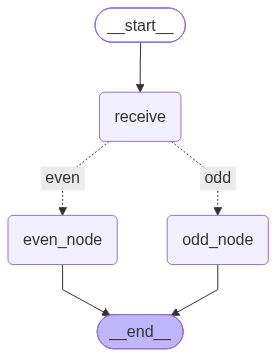

In [2]:
from typing import TypedDict, Annotated
from operator import add
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

# Define state
class ChatState(TypedDict):
    messages: Annotated[list, add]
    turn: int

# Create graph
builder = StateGraph(ChatState)

# Receive node
def receive(state: ChatState):
    if state["turn"] % 2 == 0:
        return "even"
    return "odd"

# Even node
def even_node(state: ChatState):
    return {"messages": ["Even number"]}

# Odd node
def odd_node(state: ChatState):
    return {"messages": ["Odd number"]}

# Add nodes
builder.add_node("receive", receive)
builder.add_node("even_node", even_node)
builder.add_node("odd_node", odd_node)

# Add edges
builder.add_edge(START, "receive")

builder.add_conditional_edges(
    "receive",
    receive,
    {
        "even": "even_node",
        "odd": "odd_node"
    }
)

builder.add_edge("even_node", END)
builder.add_edge("odd_node", END)

# Compile and display
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END

class NumberState(TypedDict):
    number: int
    result: str

def receive_number(state: NumberState) -> dict:
    #Enter node - just prints and passes the number through uncharged.
    print(f"Recived number: {state['number']}")
    return{}

def route_even_or_odd(state: NumberState) -> Literal["even","odd"]:
    #Return 'even' or 'odd' based on the number in state.
    if state["number"] % 2 == 0:
        return "even"
    else:
        return "odd"

def even_node(state: NumberState) -> dict:
    msg = f"{state['number']} is EVEN"
    print(f"[even_node] {msg}")
    return {"result": msg}

def odd_node(state: NumberState) -> dict:
    msg = f"{state['number']} is ODD"
    print(f"[odd_node] {msg}")

builder = StateGraph(NumberState)

builder.add_node("receive", receive_number)
builder.add_node("even_node", even_node)
builder.add_node("odd_node", odd_node)

builder.add_edge(START, "receive")

builder.add_conditional_edges(
    "receive", route_even_or_odd,
    {
        "even":"even_node","odd":"odd_node"
    }

)

builder.add_edge("even_node",END)

